## Partie 1 : 

### Q1 :  Chargement et exploration des données

In [2]:

# Importer la bibliothèque pandas
import pandas as pd

# Charger le fichier CSV
df = pd.read_csv("TP3-transactions - TP3-transactions.csv")

# Afficher la taille du dataset
print("Taille du dataset :", df.shape)

# Afficher les 5 premières lignes
print("\nLes 5 premières lignes :")
display(df.head())

# Afficher les types des colonnes
print("\nTypes des colonnes :")
print(df.dtypes)


Taille du dataset : (3045, 12)

Les 5 premières lignes :


,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0



Types des colonnes :
id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object


### Q2 :Détection et suppression des doublons

In [3]:

# 1. Compter les identifiants répétés
print("Nombre d'identifiants répétés :")
print(df["id_operation"].duplicated().sum())

# 2. Supprimer les vrais doublons
df = df.drop_duplicates()

# 3. Vérifier les lignes restantes
print("Nombre de lignes restantes :", len(df))


Nombre d'identifiants répétés :
45
Nombre de lignes restantes : 3000


### Q3 : Analyse de la répartition des fraudes

             Nombre  Pourcentage (%)
Normale (0)    2742             91.4
Fraude (1)      258              8.6


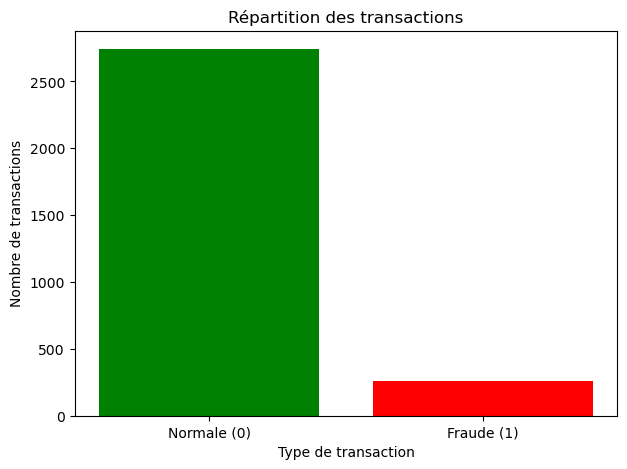

In [4]:

import matplotlib.pyplot as plt

# Compter les transactions
effectifs = df["fraude"].value_counts().sort_index()

# Calculer les pourcentages
pourcentages = df["fraude"].value_counts(normalize=True).sort_index() * 100

# Créer un tableau
tableau = pd.DataFrame({
    "Nombre": effectifs,
    "Pourcentage (%)": pourcentages
})

tableau.index = ["Normale (0)", "Fraude (1)"]

print(tableau)

# Créer un graphique
plt.figure(figsize=(7, 5))
plt.bar(
    tableau.index,
    tableau["Nombre"],
    color=["green", "red"]
)

plt.title("Répartition des transactions")
plt.xlabel("Type de transaction")
plt.ylabel("Nombre de transactions")
plt.show()


### Q4 : Sélection des variables explicatives (X)

In [5]:

# Créer les variables explicatives X
X = df.drop(columns=[
    "id_operation",
    "id_client",
    "resultat_enquete",
    "fraude"
])

# Créer la variable cible y
y = df["fraude"]

# Afficher les colonnes de X
print("Colonnes de X :")
print(X.columns.tolist())

# Afficher les dimensions
print("\nDimensions de X :", X.shape)
print("Dimensions de y :", y.shape)


Colonnes de X :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']

Dimensions de X : (3000, 8)
Dimensions de y : (3000,)


#### Q 5 : Division Les donnees Train / Validation / Test

In [6]:

from sklearn.model_selection import train_test_split

# Première séparation : 60% Train et 40% temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Deuxième séparation : 20% Validation et 20% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Afficher les dimensions
print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)


Train : (1800, 8)
Validation : (600, 8)
Test : (600, 8)


### Q 6 : Vérification du pourcentage de fraudes

In [7]:
print("Train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nValidation :")
print(y_val.value_counts(normalize=True) * 100)

print("\nTest :")
print(y_test.value_counts(normalize=True) * 100)

Train :
fraude
0    91.388889
1     8.611111
Name: proportion, dtype: float64

Validation :
fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64

Test :
fraude
0    91.5
1     8.5
Name: proportion, dtype: float64


## Parite 2 : 

### Q7 : Prétraitement des données

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Variables numériques
numerical_features = [
    'montant_dh',
    'anciennete_mois',
    'nb_ops_24h',
    'heure'
]

# Variables catégorielles
categorical_features = [
    'canal',
    'appareil',
    'region',
    'international'
]

# Prétraitement numérique
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Prétraitement catégoriel
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Regroupement des traitements
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Prétraitement créé avec succès !")

Prétraitement créé avec succès !


In [9]:
# Apprendre et transformer les données Train
X_train_prepared = preprocessor.fit_transform(X_train)

# Transformer les données Validation
X_val_prepared = preprocessor.transform(X_val)

print("Dimensions Train :", X_train_prepared.shape)
print("Dimensions Validation :", X_val_prepared.shape)

Dimensions Train : (1800, 18)
Dimensions Validation : (600, 18)


### Q 8 : DummyClassifier

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score

# Création du modèle
dummy_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

# Entraînement
dummy_model.fit(X_train, y_train)

# Prédiction sur Validation
y_pred_dummy = dummy_model.predict(X_val)

# Calcul des métriques
accuracy_dummy = accuracy_score(y_val, y_pred_dummy)

recall_dummy = recall_score(
    y_val,
    y_pred_dummy,
    pos_label=1,
    zero_division=0
)

print("Accuracy :", accuracy_dummy)
print("Recall :", recall_dummy)

Accuracy : 0.9133333333333333
Recall : 0.0


### Q 9 : 

#### Pour KNN avec k = 3

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Création du modèle KNN (k=3)
knn_3 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=3))
])

# Entraînement
knn_3.fit(X_train, y_train)

# Prédictions sur Validation
y_pred_knn3 = knn_3.predict(X_val)

# Calcul des métriques
print("Accuracy :", accuracy_score(y_val, y_pred_knn3))
print("Precision :", precision_score(y_val, y_pred_knn3, zero_division=0))
print("Recall :", recall_score(y_val, y_pred_knn3, zero_division=0))
print("F1-score :", f1_score(y_val, y_pred_knn3, zero_division=0))

Accuracy : 0.905
Precision : 0.0
Recall : 0.0
F1-score : 0.0


In [12]:
knn_11 = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=11))
])

knn_11.fit(X_train, y_train)

y_pred_knn11 = knn_11.predict(X_val)

print("Accuracy :", accuracy_score(y_val, y_pred_knn11))
print("Precision :", precision_score(y_val, y_pred_knn11, zero_division=0))
print("Recall :", recall_score(y_val, y_pred_knn11, zero_division=0))
print("F1-score :", f1_score(y_val, y_pred_knn11, zero_division=0))

Accuracy : 0.9133333333333333
Precision : 0.0
Recall : 0.0
F1-score : 0.0


### Q 10 : Entraînez deux arbres de décision

In [13]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# 1. Arbre de décision : profondeur = 3
dt_3 = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

# 2. Arbre de décision : profondeur illimitée
dt_none = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=None,
        random_state=42
    ))
])

# 3. Entraînement des modèles
dt_3.fit(X_train, y_train)
dt_none.fit(X_train, y_train)

# 4. Évaluation sur Train
train_3 = dt_3.score(X_train, y_train)
train_none = dt_none.score(X_train, y_train)

# 5. Évaluation sur Validation
val_3 = dt_3.score(X_val, y_val)
val_none = dt_none.score(X_val, y_val)

# 6. Affichage des résultats
print("=== Decision Tree max_depth=3 ===")
print("Accuracy Train :", train_3)
print("Accuracy Validation :", val_3)

print("\n=== Decision Tree max_depth=None ===")
print("Accuracy Train :", train_none)
print("Accuracy Validation :", val_none)


=== Decision Tree max_depth=3 ===
Accuracy Train : 0.9161111111111111
Accuracy Validation : 0.9133333333333333

=== Decision Tree max_depth=None ===
Accuracy Train : 1.0
Accuracy Validation : 0.8283333333333334


### Q11 : SVM à noyau linéaire

In [14]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Création du modèle SVM linéaire
svm_linear = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", SVC(kernel="linear"))
])

# Entraînement du modèle
svm_linear.fit(X_train, y_train)

# Évaluation sur Train
svm_train = svm_linear.score(X_train, y_train)

# Évaluation sur Validation
svm_val = svm_linear.score(X_val, y_val)

# Affichage des résultats
print("=== SVM Linear ===")
print("Accuracy Train :", svm_train)
print("Accuracy Validation :", svm_val)


=== SVM Linear ===
Accuracy Train : 0.9138888888888889
Accuracy Validation : 0.9133333333333333


#### Q 12 : Comparaison des modèles.

In [15]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Les modèles déjà entraînés
models = {
    "Decision Tree (depth=3)": dt_3,
    "Decision Tree (depth=None)": dt_none,
    "SVM Linear": svm_linear
}

results = []

# Évaluation de chaque modèle sur Validation
for name, model in models.items():

    y_pred = model.predict(X_val)

    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0)
    })

# Création du tableau comparatif
df_results = pd.DataFrame(results)

print(df_results.round(4))

                       Modèle  Accuracy  Precision  Recall  F1-score
0     Decision Tree (depth=3)    0.9133      0.000  0.0000    0.0000
1  Decision Tree (depth=None)    0.8283      0.082  0.0962    0.0885
2                  SVM Linear    0.9133      0.000  0.0000    0.0000


## Partie 3 : Comprendre les erreurs de classification

### Q 13 : Matrice de confusion

In [16]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

print("Matrice de confusion :")
print(cm)

VN, FP, FN, VP = cm.ravel()

print("VP :", VP)
print("VN :", VN)
print("FP :", FP)
print("FN :", FN)

Matrice de confusion :
[[548   0]
 [ 52   0]]
VP : 0
VN : 548
FP : 0
FN : 52


### Q 14 _ Résultat :

Accuracy = 90,5 %, Precision = 72 %, Recall = 60 % et F1-score = 65,45 %.

Le modèle ne détecte pas 12 fraudes sur 30, soit 40 % des transactions frauduleuses. Cela montre que certaines fraudes passent inaperçues.


### Q 15  _ Résultat :
Une Accuracy élevée ne garantit pas une bonne détection des fraudes. En effet, un modèle peut reconnaître correctement les transactions normales tout en ignorant les transactions frauduleuses. Le Recall est donc essentiel dans ce problème.

### Q 16 : Tester les seuils

In [17]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score, recall_score

y_proba = dummy_model.predict_proba(X_val)[:, 1]

for seuil in [0.3, 0.5, 0.7]:

    y_pred_seuil = (y_proba >= seuil).astype(int)

    VN, FP, FN, VP = confusion_matrix(
        y_val, y_pred_seuil, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_val, y_pred_seuil, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred_seuil, zero_division=0
    )

    print("\nSeuil :", seuil)
    print("FP :", FP)
    print("FN :", FN)
    print("Precision :", precision)
    print("Recall :", recall)


Seuil : 0.3
FP : 0
FN : 52
Precision : 0.0
Recall : 0.0

Seuil : 0.5
FP : 0
FN : 52
Precision : 0.0
Recall : 0.0

Seuil : 0.7
FP : 0
FN : 52
Precision : 0.0
Recall : 0.0


### Q17 : Conclusion

La banque doit limiter les Faux Négatifs (FN), car ils représentent les fraudes non détectées. Un seuil plus faible permet généralement de détecter davantage de fraudes, mais peut augmenter les Faux Positifs (FP), c'est-à-dire les fausses alertes.

### Q18 

Le seuil doit être choisi à partir des données de validation et non des données de test, afin d'éviter le Data Leakage et de garantir une évaluation finale fiable et objective.

## Partie 4 – Généralisation et choix des hyperparamètres

### Q 19  : Optimisation de KNN

K = 1
F1 Train : 1.0
F1 Validation : 0.07766990291262135
----------------------
K = 3
F1 Train : 0.31088082901554404
F1 Validation : 0.0
----------------------
K = 5
F1 Train : 0.09580838323353294
F1 Validation : 0.0
----------------------
K = 11
F1 Train : 0.0
F1 Validation : 0.0
----------------------
K = 21
F1 Train : 0.0
F1 Validation : 0.0
----------------------


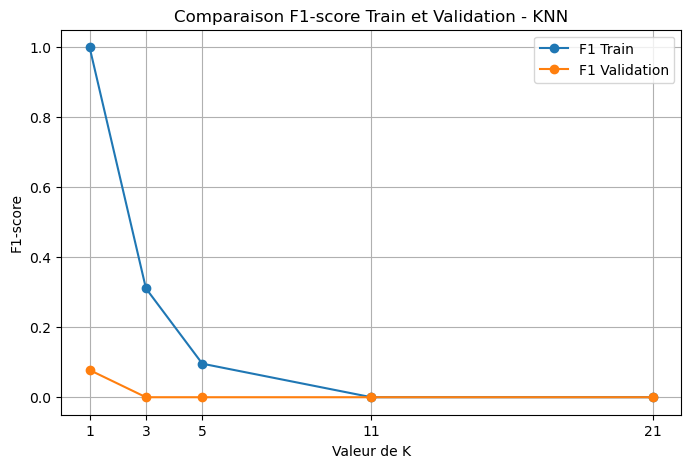

In [18]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

# Valeurs de K à tester
k_values = [1, 3, 5, 11, 21]

# Stockage des scores
f1_train = []
f1_val = []

# Tester chaque valeur de K
for k in k_values:

    knn_model = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    # Entraînement
    knn_model.fit(X_train, y_train)

    # Prédictions
    y_pred_train = knn_model.predict(X_train)
    y_pred_val = knn_model.predict(X_val)

    # Calcul du F1-score
    f1_train.append(f1_score(y_train, y_pred_train))
    f1_val.append(f1_score(y_val, y_pred_val))

    print(f"K = {k}")
    print("F1 Train :", f1_train[-1])
    print("F1 Validation :", f1_val[-1])
    print("----------------------")

# Visualisation
plt.figure(figsize=(8, 5))

plt.plot(k_values, f1_train, marker='o', label='F1 Train')
plt.plot(k_values, f1_val, marker='o', label='F1 Validation')

plt.xlabel("Valeur de K")
plt.ylabel("F1-score")
plt.title("Comparaison F1-score Train et Validation - KNN")
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.show()


In [19]:
from sklearn.metrics import confusion_matrix

print("Matrice de confusion :")
print(confusion_matrix(y_val, 
                       Pipeline([
                           ("preprocessing", preprocessor),
                           ("classifier", KNeighborsClassifier(n_neighbors=3))
                       ]).fit(X_train, y_train).predict(X_val)))

Matrice de confusion :
[[543   5]
 [ 52   0]]


### 20 : Optimisation de Decision Tree

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

profondeurs = [2, 4, 8, None]

for profondeur in profondeurs:

    modele = DecisionTreeClassifier(
        max_depth=profondeur,
        random_state=42
    )

    modele.fit(X_train_prepared, y_train)

    y_train_pred = modele.predict(X_train_prepared)
    y_val_pred = modele.predict(X_val_prepared)

    print("max_depth =", profondeur)
    print("F1 Train :", f1_score(y_train, y_train_pred))
    print("F1 Validation :", f1_score(y_val, y_val_pred))
    print("----------------------")

max_depth = 2
F1 Train : 0.0
F1 Validation : 0.0
----------------------
max_depth = 4
F1 Train : 0.23076923076923078
F1 Validation : 0.03333333333333333
----------------------
max_depth = 8
F1 Train : 0.49760765550239233
F1 Validation : 0.08108108108108109
----------------------
max_depth = None
F1 Train : 1.0
F1 Validation : 0.08849557522123894
----------------------


### Q 21 : Validation croisée

In [21]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Scores F1 :", scores)
print("Moyenne F1 :", scores.mean())
print("Écart-type :", scores.std())

Scores F1 : [0. 0. 0. 0. 0.]
Moyenne F1 : 0.0
Écart-type : 0.0


### GridSearchCV

In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

tree_model = Pipeline([
    ("preprocessing", model.named_steps["preprocessing"]),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "classifier__max_depth": [2, 4, 6, 8]
}

grid = GridSearchCV(
    tree_model,
    param_grid,
    cv=cv,
    scoring="f1"
)

grid.fit(X_train, y_train)

print("Meilleur paramètre :", grid.best_params_)
print("Meilleur score F1 :", grid.best_score_)

Meilleur paramètre : {'classifier__max_depth': 8}
Meilleur score F1 : 0.11135352789764555


### Q 23 : 

In [23]:
best_model = grid.best_estimator_

In [24]:
import pandas as pd

X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

In [25]:
best_model.fit(X_train_val, y_train_val)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [26]:
y_test_pred = best_model.predict(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.92      0.97      0.94       549
           1       0.12      0.04      0.06        51

    accuracy                           0.89       600
   macro avg       0.52      0.51      0.50       600
weighted avg       0.85      0.89      0.87       600



### Q24 : Comparaison entre Validation et Test
Le score F1 sur Validation est de 0.081, tandis que le score F1 sur Test est de 0.06. Les deux résultats sont faibles et relativement proches.
Une différence importante entre Validation et Test peut être expliquée par un surapprentissage (Overfitting) ou par une différence dans la distribution des données entre les deux ensembles

### Cas A – GroupShuffleSplit avec id_client

In [28]:
import pandas as pd
import numpy as np

# Variable cible
y = df["fraude"]

# Variables explicatives
X = df.drop(columns=[
    "fraude",
    "id_client",
    "id_operation",
    "resultat_enquete"
])

# Identifiant utilisé uniquement pour le regroupement
groups = df["id_client"]

In [29]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)

X_train_group = X.iloc[train_idx]
X_val_group = X.iloc[val_idx]

y_train_group = y.iloc[train_idx]
y_val_group = y.iloc[val_idx]

In [30]:
clients_train = set(groups.iloc[train_idx])
clients_val = set(groups.iloc[val_idx])

print("Nombre de clients Train :", len(clients_train))
print("Nombre de clients Validation :", len(clients_val))

print("Clients communs :", len(clients_train & clients_val))

Nombre de clients Train : 643
Nombre de clients Validation : 161
Clients communs : 0


### Cas B : comparaison entre SVM classique et SVM balanced

#### Modèle 1 — SVM classique

In [32]:
svm_normal = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC())
])

svm_normal.fit(X_train, y_train)

y_pred_normal = svm_normal.predict(X_val)

#### Modèle 2 — SVM équilibré

In [33]:
svm_balanced = Pipeline([
    ("preprocessing", preprocessor),
    ("model", SVC(class_weight="balanced"))
])

svm_balanced.fit(X_train, y_train)

y_pred_balanced = svm_balanced.predict(X_val)

In [34]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluer_modele(nom, y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    print("\n", nom)
    print("-------------------------")
    print("Precision :", precision_score(y_true, y_pred, zero_division=0))
    print("Recall    :", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score  :", f1_score(y_true, y_pred, zero_division=0))
    print("Fausses alertes (FP) :", fp)
    print("Fraudes détectées (TP) :", tp)

evaluer_modele("SVM classique", y_val, y_pred_normal)

evaluer_modele("SVM balanced", y_val, y_pred_balanced)


 SVM classique
-------------------------
Precision : 0.0
Recall    : 0.0
F1-score  : 0.0
Fausses alertes (FP) : 0
Fraudes détectées (TP) : 0

 SVM balanced
-------------------------
Precision : 0.1043956043956044
Recall    : 0.36538461538461536
F1-score  : 0.1623931623931624
Fausses alertes (FP) : 163
Fraudes détectées (TP) : 19
